# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Vocabulary size:", len(tokenizer.word_index))
print("Maximum question length:", X.shape[1])

X shape: torch.Size([168, 11])
y shape: torch.Size([168])
Vocabulary size: 226
Maximum question length: 11


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Convert word IDs into vectors
        self.emb = nn.Embedding(
            len(tokenizer.word_index) + 1,
            16
        )

        # Read each question word-by-word
        self.rnn = nn.RNN(
            16,
            32,
            batch_first=True
        )

        # Attention score for every word
        self.att = nn.Linear(32, 1)

        # Predict one of the 12 answer groups
        self.fc = nn.Linear(
            32,
            df["answer_id"].nunique()
        )

    def forward(self, x):

        x = self.emb(x)

        x, _ = self.rnn(x)

        weights = torch.softmax(
            self.att(x),
            dim=1
        )

        context = (x * weights).sum(1)

        output = self.fc(context)

        return output, weights.squeeze(-1)


model = RNN()

print(model)

RNN(
  (emb): Embedding(227, 16)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):

    optimizer.zero_grad()

    output, weights = model(X)

    loss = nn.functional.cross_entropy(output, y)

    loss.backward()

    optimizer.step()

print("Training finished!")
print("Final loss:", loss.item())

Training finished!
Final loss: 0.049643050879240036


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

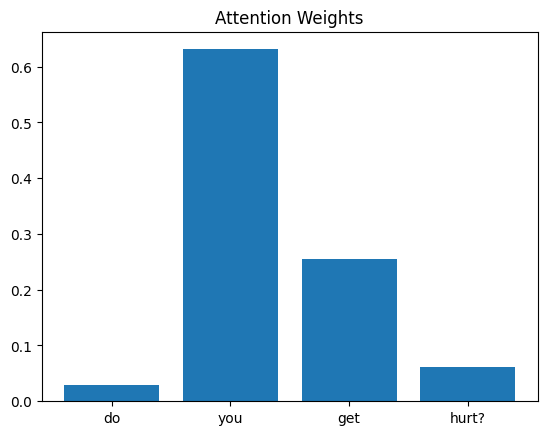

In [9]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention word: you


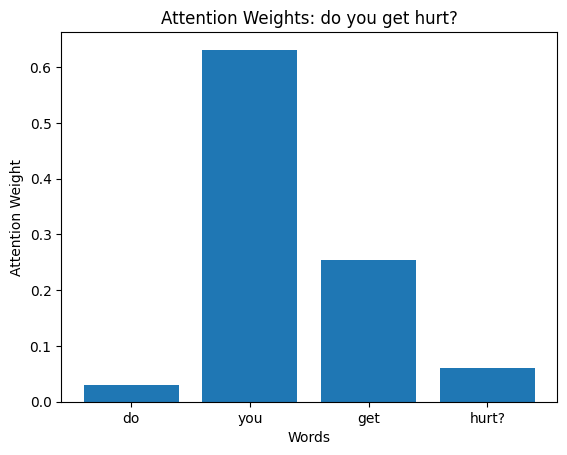

Question: who built you?
Highest attention word: who


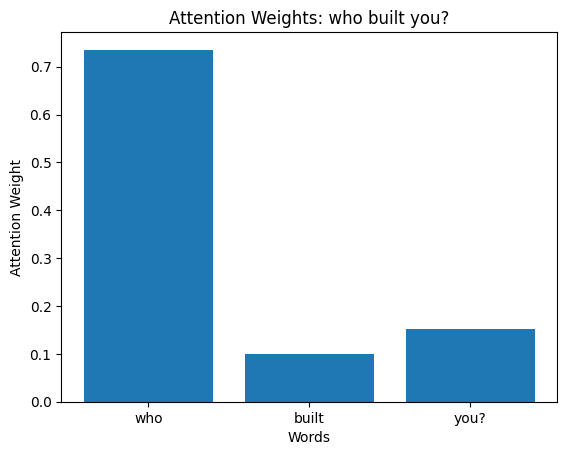

Question: what is your purpose?
Highest attention word: what


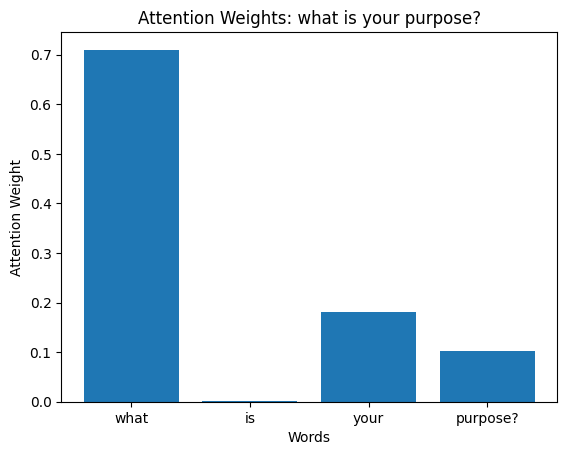

In [10]:
# Select three questions from different answer groups
question_indices = [0, 46, 70]

for idx in question_indices:

    question = df["question"][idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    # Keep attention weights only for real words
    word_weights = weights[0, :len(words)]

    # Find word with highest attention
    highest_index = torch.argmax(word_weights).item()
    highest_word = words[highest_index]

    print("Question:", question)
    print("Highest attention word:", highest_word)

    # Attention chart
    plt.figure()
    plt.bar(words, word_weights.tolist())
    plt.title("Attention Weights: " + question)
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

The words with the highest attention weights were “you” for “do you get hurt?”, “who” for “who built you?”, and “what” for “what is your purpose?”. In the second and third questions, the highest-attention words are clearly important because “who” identifies that the question is asking about a creator, while “what” indicates that the question is asking about purpose. In the first question, “you” receives the highest attention, although “hurt” may seem more meaningful to a human reader. This shows that the model does not always focus on the same words that a person would consider most important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: who programmed you?
Highest attention word: who


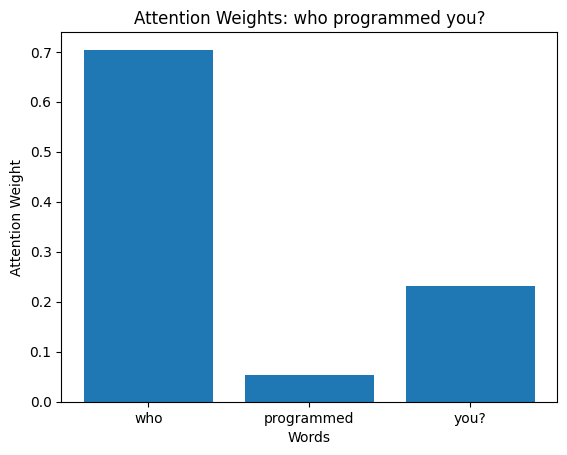

Question: who built you?
Highest attention word: who


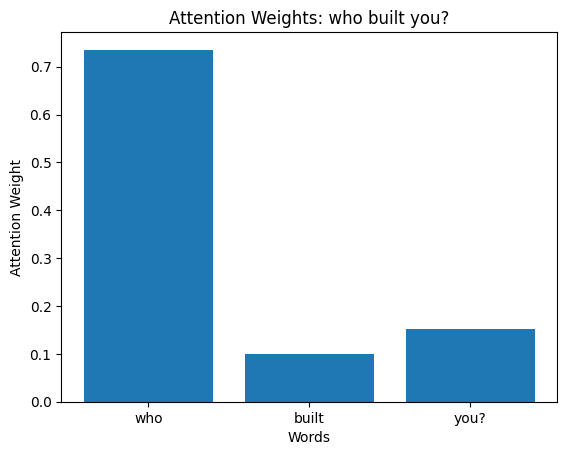

In [11]:
question_indices = [42, 46]

for idx in question_indices:

    question = df["question"][idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    word_weights = weights[0, :len(words)]

    highest_index = torch.argmax(word_weights).item()
    highest_word = words[highest_index]

    print("Question:", question)
    print("Highest attention word:", highest_word)

    plt.figure()
    plt.bar(words, word_weights.tolist())
    plt.title("Attention Weights: " + question)
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

For both “who programmed you?” and “who built you?”, the model gave the highest attention weight to the word “who”. This means the model focused on the same key word even though the rest of the wording was different. Since both questions ask about the creator of the system, focusing on “who” is reasonable. This suggests that the attention mechanism can identify similar important information across questions that have similar meanings but different wording.